# Learning an image retrieval embedding

Do triplet-trained embeddings retrieve the right digit class more often than raw pixels?

I train an encoder with sampled anchor, positive and negative images, then evaluate nearest-neighbor retrieval. The project links the image retrieval laboratory to HSE's metric learning assignment.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import json
import os
from pathlib import Path
import sys

import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from vision_projects.training import (
    Trainer,
    TrainConfig,
    digits_data,
    image_grid,
    plot_history,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "09_metric_learning"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Data and split

The 1,797 handwritten digit images come from `sklearn.datasets.load_digits`. Intensities are divided by the known sensor maximum of 16. The original 8 by 8 images are resized to 16 by 16 for the convolutional experiments. Resizing adds no measured detail. The split is stratified: 60% train, 20% validation and 20% test.

{'train': 1077, 'validation': 360, 'test': 360}


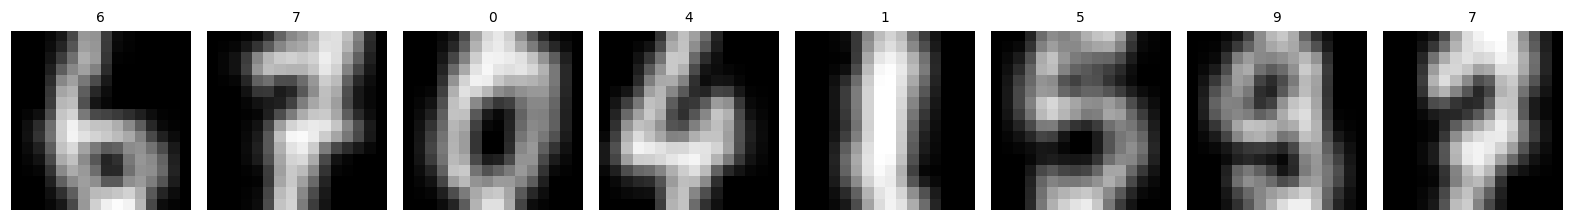

In [5]:
from vision_projects.models import EmbeddingCNN

data = digits_data()
train_loader, validation_loader, test_loader = data.loaders()
train_images, train_labels = data.train.tensors
print(
    {
        "train": len(data.train),
        "validation": len(data.validation),
        "test": len(data.test),
    }
)
image_grid(train_images[:8], output / "examples.png", train_labels[:8].tolist())

## Triplets and margin

The triplet objective is $\max(0, d(a,p) - d(a,n) + m)$. A positive shares the anchor label but is a different training image. Negatives come from other classes. Unit-normalized vectors make Euclidean distances comparable across images.

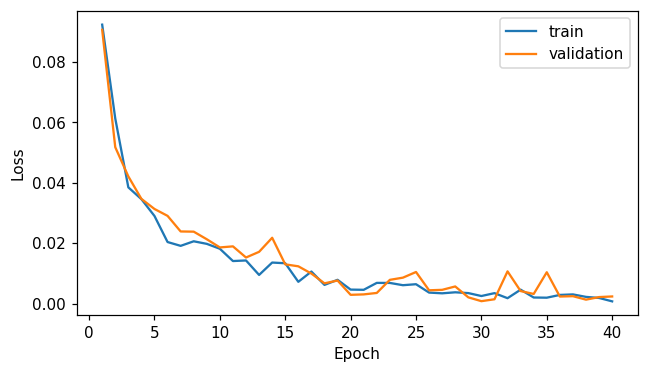

In [7]:
class DigitTriplets(torch.utils.data.Dataset):
    def __init__(self, dataset):
        self.images, self.labels = dataset.tensors
        self.groups = {
            int(label): torch.where(self.labels == label)[0]
            for label in self.labels.unique()
        }

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        label = int(self.labels[index])
        positive_ids = self.groups[label]
        positive_ids = positive_ids[positive_ids != index]
        negative_ids = torch.where(self.labels != label)[0]
        positive = positive_ids[torch.randint(len(positive_ids), ())]
        negative = negative_ids[torch.randint(len(negative_ids), ())]
        return torch.stack(
            [self.images[index], self.images[positive], self.images[negative]]
        ), torch.tensor(0)


class TripletModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = EmbeddingCNN()

    def forward(self, images):
        batch = len(images)
        return self.encoder(images.flatten(0, 1)).reshape(batch, 3, -1)


class TripletLoss(nn.Module):
    def forward(self, embeddings, _):
        anchor, positive, negative = embeddings.unbind(1)
        return F.triplet_margin_loss(anchor, positive, negative, margin=0.3)


triplets = DataLoader(DigitTriplets(data.train), batch_size=64, shuffle=True)
validation_triplets = DigitTriplets(data.validation)
fixed_triplets = [validation_triplets[i] for i in range(len(validation_triplets))]
fixed_validation = DataLoader(
    TensorDataset(
        torch.stack([row[0] for row in fixed_triplets]),
        torch.zeros(len(fixed_triplets)),
    ),
    batch_size=64,
)
model = TripletModel()
history = Trainer(model, TripletLoss(), TrainConfig(epochs=EPOCHS)).fit(
    triplets, fixed_validation
)
plot_history(history, output / "triplet_loss.png")

## Separate gallery and query

The training images form the gallery and test images form independent queries. Every query has relevant gallery items of the same class. Recall@k here is the fraction of all relevant gallery items returned; hit@k records whether at least one relevant item appears.

In [9]:
gallery_images, gallery_labels = data.train.tensors
query_images, query_labels = data.test.tensors
model.eval()
with torch.inference_mode():
    gallery = model.encoder(gallery_images)
    queries = model.encoder(query_images)
pixel_gallery = F.normalize(gallery_images.flatten(1), dim=-1)
pixel_queries = F.normalize(query_images.flatten(1), dim=-1)


def retrieval_metrics(query_vectors, gallery_vectors):
    ranking = torch.cdist(query_vectors, gallery_vectors).argsort(-1)
    relevant = gallery_labels[ranking] == query_labels[:, None]
    total_relevant = (gallery_labels[None] == query_labels[:, None]).sum(-1)
    rows = {}
    for k in [1, 5, 10]:
        rows[f"precision@{k}"] = float(relevant[:, :k].float().mean())
        rows[f"recall@{k}"] = float((relevant[:, :k].sum(-1) / total_relevant).mean())
        rows[f"hit@{k}"] = float(relevant[:, :k].any(-1).float().mean())
    return rows, ranking


learned, ranking = retrieval_metrics(queries, gallery)
pixel_scores, _ = retrieval_metrics(pixel_queries, pixel_gallery)
print(pd.DataFrame({"pixels": pixel_scores, "triplet": learned}))

                pixels   triplet
precision@1   0.975000  0.994444
recall@1      0.009051  0.009234
hit@1         0.975000  0.994444
precision@5   0.964444  0.990556
recall@5      0.044754  0.045983
hit@5         0.994444  1.000000
precision@10  0.939444  0.989444
recall@10     0.087176  0.091860
hit@10        0.997222  1.000000


## Nearest-neighbor inspection

A retrieval figure shows one query followed by gallery neighbors. Class labels define relevance in this experiment; visual similarity within a class may have a different ordering. The embedding norm check confirms that the distance convention matches training.

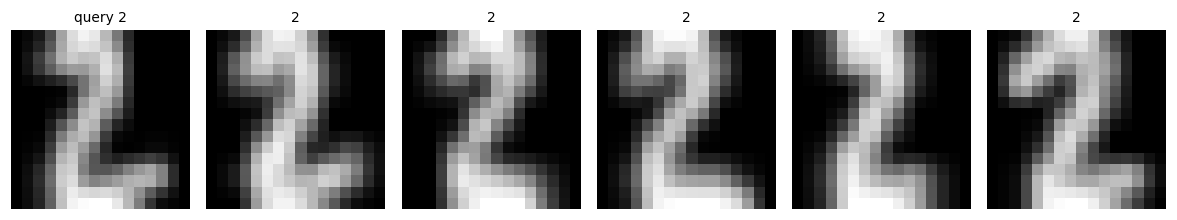

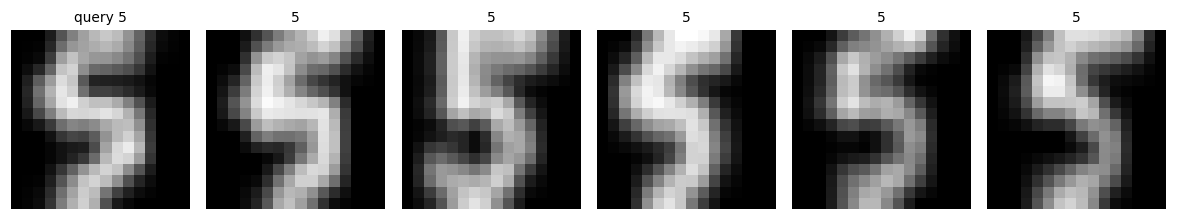

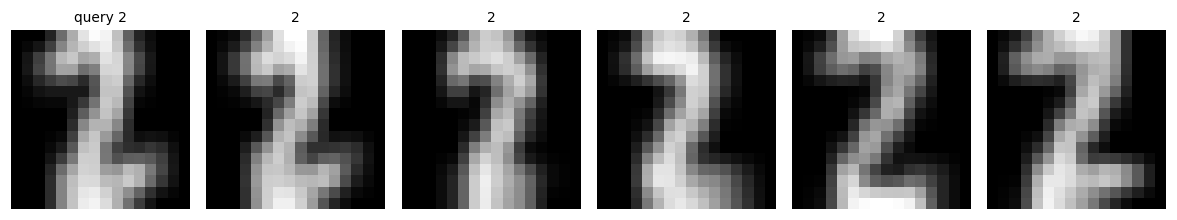

In [11]:
assert torch.allclose(gallery.norm(dim=-1), torch.ones(len(gallery)), atol=1e-5)
for index in range(3):
    images = torch.cat(
        [query_images[index : index + 1], gallery_images[ranking[index, :5]]]
    )
    titles = [f"query {int(query_labels[index])}"] + [
        str(int(label)) for label in gallery_labels[ranking[index, :5]]
    ]
    image_grid(images, output / f"neighbors_{index}.png", titles)
results = {
    "pixels": pixel_scores,
    "triplet": learned,
    "gallery_images": len(gallery),
    "query_images": len(queries),
}

## Reading the result

Nearest-neighbor retrieval uses training images as the gallery but test identities as queries. Labels are used to construct training triplets and to evaluate relevance. The class-based metric is suitable for digit retrieval and needs different relevance labels for logo or specimen retrieval.

In [13]:
result_path = root / "results" / "09_metric_learning.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/09_metric_learning.json


## Next experiment

Compare sampled triplets with batch-hard mining. Keep a separate validation query set to choose the margin and embedding dimension before evaluating test retrieval.

## Sources

UniPd Computer Vision and Cognitive Systems: uploaded filtering, SIFT, BoW, MLP and CNN notebooks. [HSE deep learning course](https://github.com/mryab/dl-hse-ami) and its [wiki syllabus](https://wiki.cs.hse.ru/Глубинное_обучение_2022). week06_vision.

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.